# Customer Churn Analysis - Exploratory Data Analysis

This notebook performs comprehensive exploratory data analysis on the telecom customer churn dataset.

## Contents
1. Data Loading and Overview
2. Data Quality Assessment
3. Univariate Analysis
4. Bivariate Analysis
5. Multivariate Analysis
6. Key Insights and Findings

In [1]:
import os
print(os.getcwd())


c:\Users\User\Desktop\Projects\customer-churn-analysis-Capestone-Project-\notebooks


In [2]:
# Import libraries
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from src.config import RAW_DATA_PATH, CATEGORICAL_FEATURES, NUMERICAL_FEATURES, TARGET
from src.data_preprocessing import load_data
from src.visualization import (
    plot_numerical_distribution,
    plot_categorical_distribution,
    plot_correlation_heatmap,
    plot_target_distribution,
    plot_churn_by_feature
)

# Settings
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
%matplotlib inline

# Suppress warnings
import warnings
warnings.filterwarnings('ignore')

## 1. Data Loading and Overview

In [3]:
# Load data
df = load_data()
print(f"Dataset shape: {df.shape}")
print(f"Number of customers: {df.shape[0]:,}")
print(f"Number of features: {df.shape[1]}")

Data loaded successfully. Shape: (3333, 20)
Dataset shape: (3333, 20)
Number of customers: 3,333
Number of features: 20


In [4]:
# First few rows
df.head(10)

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False
5,AL,118,510,Yes,No,0,223.4,98,37.98,220.6,101,18.75,203.9,118,9.18,6.3,6,1.70,0,False
6,MA,121,510,No,Yes,24,218.2,88,37.09,348.5,108,29.62,212.6,118,9.57,7.5,7,2.03,3,False
7,MO,147,415,Yes,No,0,157.0,79,26.69,103.1,94,8.76,211.8,96,9.53,7.1,6,1.92,0,False
8,LA,117,408,No,No,0,184.5,97,31.37,351.6,80,29.89,215.8,90,9.71,8.7,4,2.35,1,False
9,WV,141,415,Yes,Yes,37,258.6,84,43.96,222.0,111,18.87,326.4,97,14.69,11.2,5,3.02,0,False


In [5]:
# Data types and info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   3333 non-null   object 
 1   Account length          3333 non-null   int64  
 2   Area code               3333 non-null   int64  
 3   International plan      3333 non-null   object 
 4   Voice mail plan         3333 non-null   object 
 5   Number vmail messages   3333 non-null   int64  
 6   Total day minutes       3333 non-null   float64
 7   Total day calls         3333 non-null   int64  
 8   Total day charge        3333 non-null   float64
 9   Total eve minutes       3333 non-null   float64
 10  Total eve calls         3333 non-null   int64  
 11  Total eve charge        3333 non-null   float64
 12  Total night minutes     3333 non-null   float64
 13  Total night calls       3333 non-null   int64  
 14  Total night charge      3333 non-null   

In [6]:
# Statistical summary
df.describe()

,Account length,Area code,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,101.064806,437.182418,8.099010,179.775098,100.435644,30.562307,200.980348,100.114311,17.083540,200.872037,100.107711,9.039325,10.237294,4.479448,2.764581,1.562856
std,39.822106,42.371290,13.688365,54.467389,20.069084,9.259435,50.713844,19.922625,4.310668,50.573847,19.568609,2.275873,2.791840,2.461214,0.753773,1.315491
min,1.000000,408.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,23.200000,33.000000,1.040000,0.000000,0.000000,0.000000,0.000000
25%,74.000000,408.000000,0.000000,143.700000,87.000000,24.430000,166.600000,87.000000,14.160000,167.000000,87.000000,7.520000,8.500000,3.000000,2.300000,1.000000
50%,101.000000,415.000000,0.000000,179.400000,101.000000,30.500000,201.400000,100.000000,17.120000,201.200000,100.000000,9.050000,10.300000,4.000000,2.780000,1.000000
75%,127.000000,510.000000,20.000000,216.400000,114.000000,36.790000,235.300000,114.000000,20.000000,235.300000,113.000000,10.590000,12.100000,6.000000,3.270000,2.000000
max,243.000000,510.000000,51.000000,350.800000,165.000000,59.640000,363.700000,170.000000,30.910000,395.000000,175.000000,17.770000,20.000000,20.000000,5.400000,9.000000


## 2. Data Quality Assessment

In [7]:
# Check for missing values
missing_values = df.isnull().sum()
missing_percent = (missing_values / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percent
}).sort_values('Missing Values', ascending=False)

print("Missing Values Summary:")
print(missing_df[missing_df['Missing Values'] > 0])

Missing Values Summary:
Empty DataFrame
Columns: [Missing Values, Percentage]
Index: []


In [8]:
# Check for duplicates
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

Number of duplicate rows: 0


In [9]:
# Check unique values for categorical features
print("Unique values in categorical features:\n")
for col in CATEGORICAL_FEATURES:
    if col in df.columns:
        print(f"{col}: {df[col].nunique()} unique values")
        print(f"  Values: {df[col].unique()[:5]}..." if df[col].nunique() > 5 else f"  Values: {df[col].unique()}")
        print()

Unique values in categorical features:

State: 51 unique values
  Values: ['KS' 'OH' 'NJ' 'OK' 'AL']...

International plan: 2 unique values
  Values: ['No' 'Yes']

Voice mail plan: 2 unique values
  Values: ['Yes' 'No']



## 3. Univariate Analysis

### 3.1 Target Variable Distribution

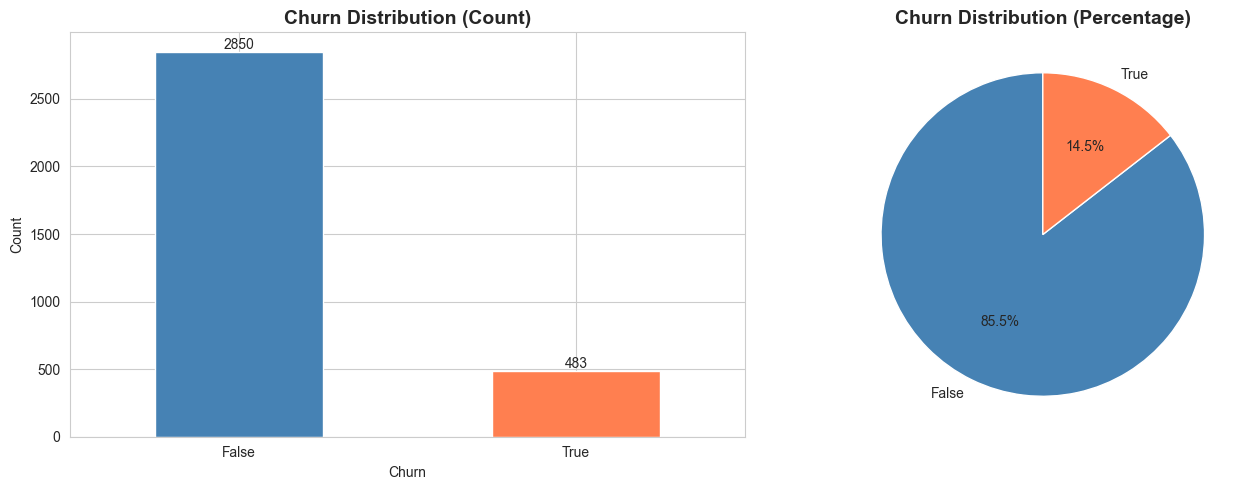


Overall Churn Rate: 0.00%


In [10]:
# Target variable distribution
plot_target_distribution(df, TARGET, save=True)

# Calculate churn rate
churn_rate = (df[TARGET] == 'Yes').mean() * 100
print(f"\nOverall Churn Rate: {churn_rate:.2f}%")

### 3.2 Numerical Features Distribution

In [11]:
# Statistical summary of numerical features
df[NUMERICAL_FEATURES].describe()

,Account length,Area code,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,101.064806,437.182418,8.099010,179.775098,100.435644,30.562307,200.980348,100.114311,17.083540,200.872037,100.107711,9.039325,10.237294,4.479448,2.764581,1.562856
std,39.822106,42.371290,13.688365,54.467389,20.069084,9.259435,50.713844,19.922625,4.310668,50.573847,19.568609,2.275873,2.791840,2.461214,0.753773,1.315491
min,1.000000,408.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,23.200000,33.000000,1.040000,0.000000,0.000000,0.000000,0.000000
25%,74.000000,408.000000,0.000000,143.700000,87.000000,24.430000,166.600000,87.000000,14.160000,167.000000,87.000000,7.520000,8.500000,3.000000,2.300000,1.000000
50%,101.000000,415.000000,0.000000,179.400000,101.000000,30.500000,201.400000,100.000000,17.120000,201.200000,100.000000,9.050000,10.300000,4.000000,2.780000,1.000000
75%,127.000000,510.000000,20.000000,216.400000,114.000000,36.790000,235.300000,114.000000,20.000000,235.300000,113.000000,10.590000,12.100000,6.000000,3.270000,2.000000
max,243.000000,510.000000,51.000000,350.800000,165.000000,59.640000,363.700000,170.000000,30.910000,395.000000,175.000000,17.770000,20.000000,20.000000,5.400000,9.000000


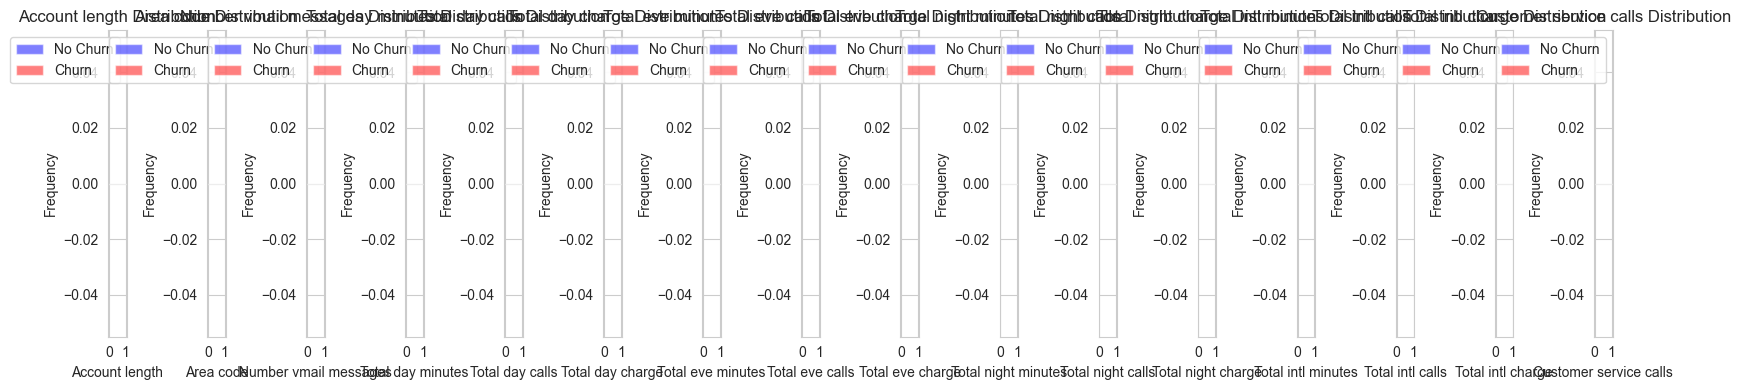

In [12]:
# Distribution of numerical features
plot_numerical_distribution(df, NUMERICAL_FEATURES, TARGET, save=True)

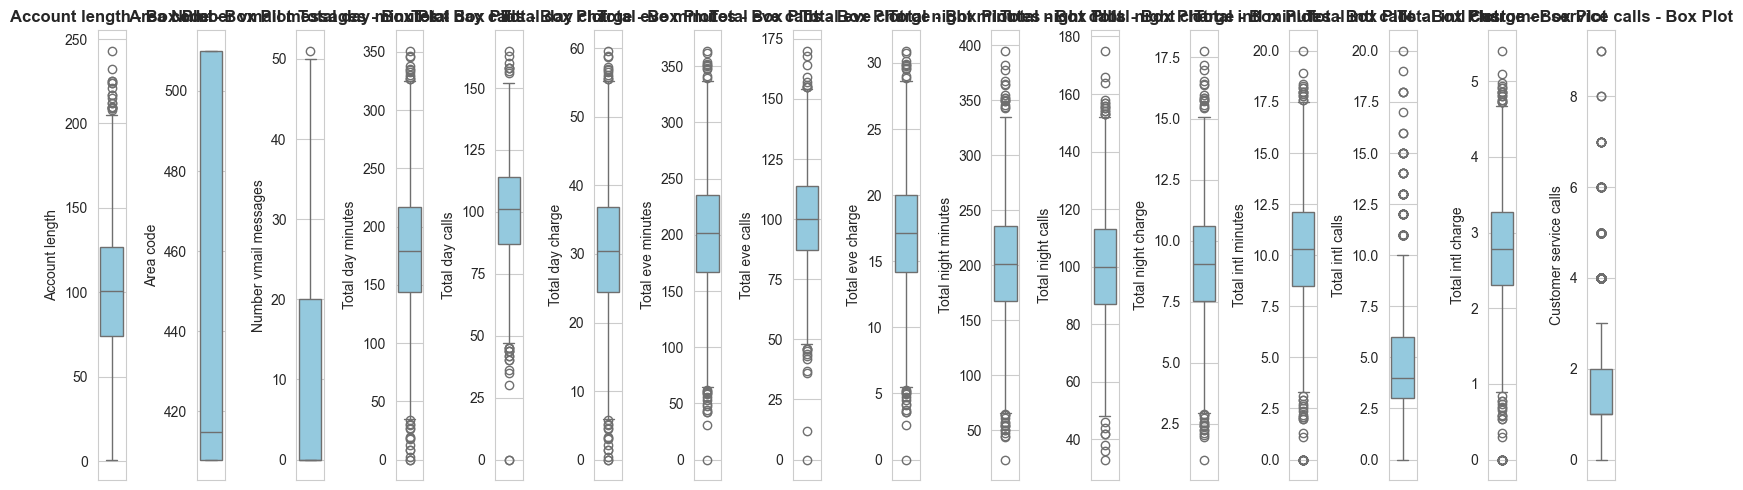

In [20]:
# Box plots for outlier detection
fig, axes = plt.subplots(1, len(NUMERICAL_FEATURES), figsize=(16, 5))

for idx, col in enumerate(NUMERICAL_FEATURES):
    sns.boxplot(data=df, y=col, ax=axes[idx], color='skyblue')
    axes[idx].set_title(f'{col} - Box Plot', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### 3.3 Categorical Features Distribution

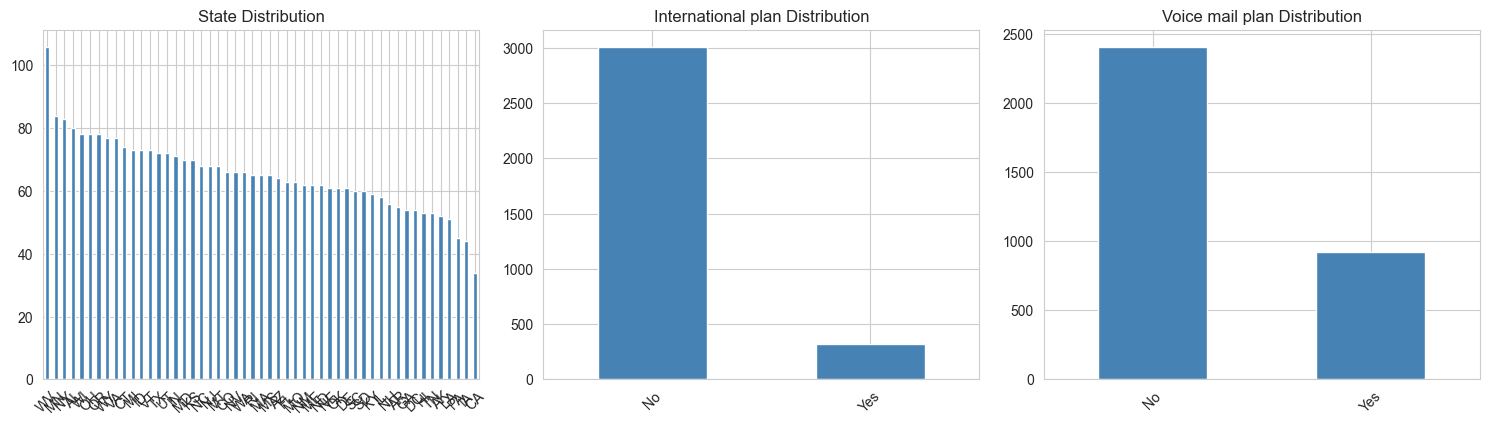

In [14]:
# Distribution of categorical features
plot_categorical_distribution(df, CATEGORICAL_FEATURES, rows=4, cols=4, save=True)

## 4. Bivariate Analysis

### 4.1 Numerical Features vs Target

In [15]:
# Statistical comparison by churn status
for col in NUMERICAL_FEATURES:
    print(f"\n{col} by Churn Status:")
    print(df.groupby(TARGET)[col].describe())
    print("-" * 80)


Account length by Churn Status:
        count        mean       std  min   25%    50%    75%    max
Churn                                                              
False  2850.0  100.793684  39.88235  1.0  73.0  100.0  127.0  243.0
True    483.0  102.664596  39.46782  1.0  76.0  103.0  127.0  225.0
--------------------------------------------------------------------------------

Area code by Churn Status:
        count        mean        std    min    25%    50%    75%    max
Churn                                                                  
False  2850.0  437.074737  42.306156  408.0  408.0  415.0  510.0  510.0
True    483.0  437.817805  42.792270  408.0  408.0  415.0  510.0  510.0
--------------------------------------------------------------------------------

Number vmail messages by Churn Status:
        count      mean        std  min  25%  50%   75%   max
Churn                                                        
False  2850.0  8.604561  13.913125  0.0  0.0  0.0  22

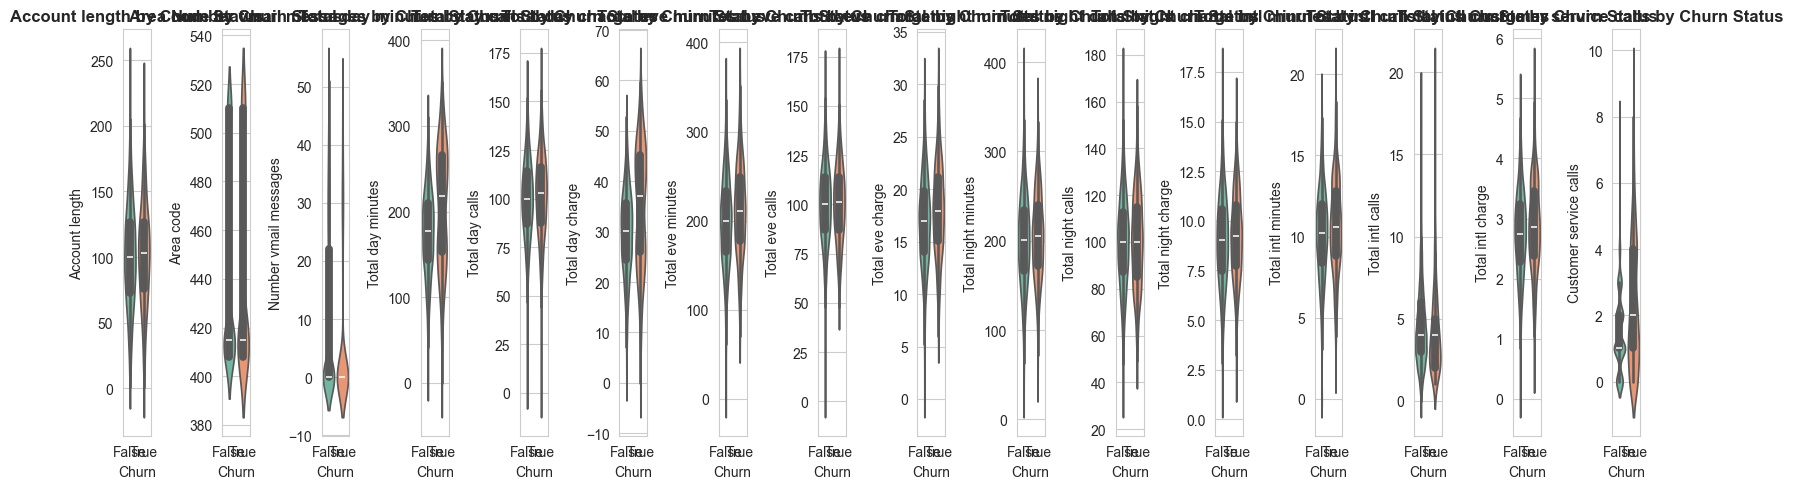

In [21]:
# Violin plots
fig, axes = plt.subplots(1, len(NUMERICAL_FEATURES), figsize=(16, 5))

for idx, col in enumerate(NUMERICAL_FEATURES):
    sns.violinplot(data=df, x=TARGET, y=col, ax=axes[idx], palette='Set2')
    axes[idx].set_title(f'{col} by Churn Status', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### 4.2 Categorical Features vs Target

In [22]:
# Churn rate by key categorical features
key_features = ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport']

for feature in key_features:
    if feature in df.columns:
        print(f"\nChurn Rate by {feature}:")
        churn_by_feature = df.groupby(feature)[TARGET].apply(lambda x: (x == 'Yes').mean() * 100)
        print(churn_by_feature.sort_values(ascending=False))
        print("-" * 80)

KeyError: 'Contract'

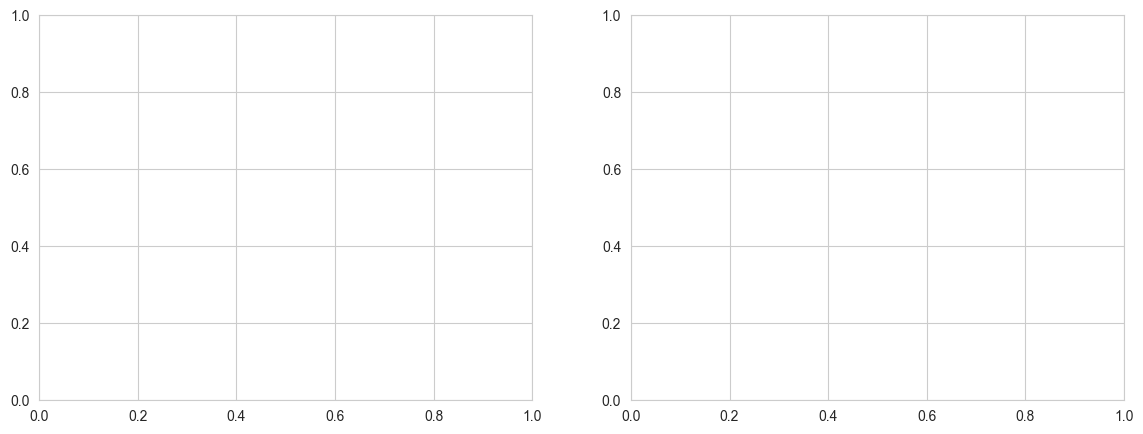

In [23]:
# Visualize churn by Contract type
plot_churn_by_feature(df, 'Contract', TARGET, save=True)

KeyError: 'InternetService'

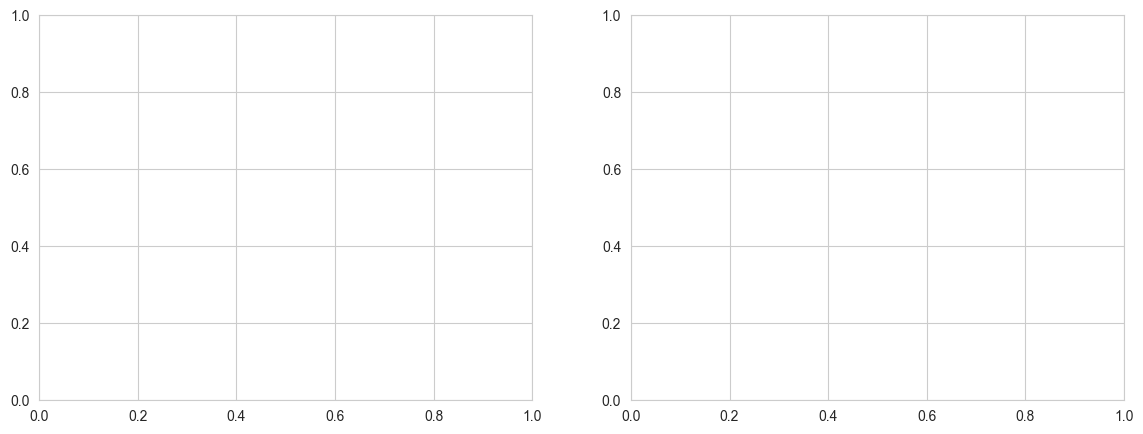

In [24]:
# Visualize churn by Internet Service
plot_churn_by_feature(df, 'InternetService', TARGET, save=True)

## 5. Multivariate Analysis

### 5.1 Correlation Analysis

In [25]:
# Convert TotalCharges to numeric if needed
df_numeric = df.copy()
df_numeric['TotalCharges'] = pd.to_numeric(df_numeric['TotalCharges'], errors='coerce')
df_numeric['Churn_Binary'] = (df_numeric[TARGET] == 'Yes').astype(int)

# Correlation heatmap
plot_correlation_heatmap(df_numeric, figsize=(12, 10), save=True)

KeyError: 'TotalCharges'

In [26]:
# Correlation with target
numeric_cols = df_numeric.select_dtypes(include=[np.number]).columns
correlations = df_numeric[numeric_cols].corrwith(df_numeric['Churn_Binary']).sort_values(ascending=False)

print("Correlation with Churn:")
print(correlations)

KeyError: 'Churn_Binary'

### 5.2 Tenure Analysis

In [ ]:
# Create tenure groups
df['tenure_group'] = pd.cut(
    df['tenure'],
    bins=[0, 12, 24, 48, 72],
    labels=['0-1 year', '1-2 years', '2-4 years', '4+ years']
)

# Churn rate by tenure group
churn_by_tenure = df.groupby('tenure_group')[TARGET].apply(lambda x: (x == 'Yes').mean() * 100)

plt.figure(figsize=(10, 6))
churn_by_tenure.plot(kind='bar', color='coral')
plt.title('Churn Rate by Tenure Group', fontsize=14, fontweight='bold')
plt.xlabel('Tenure Group', fontsize=12)
plt.ylabel('Churn Rate (%)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Churn Rate by Tenure Group:")
print(churn_by_tenure)

### 5.3 Service Adoption Analysis

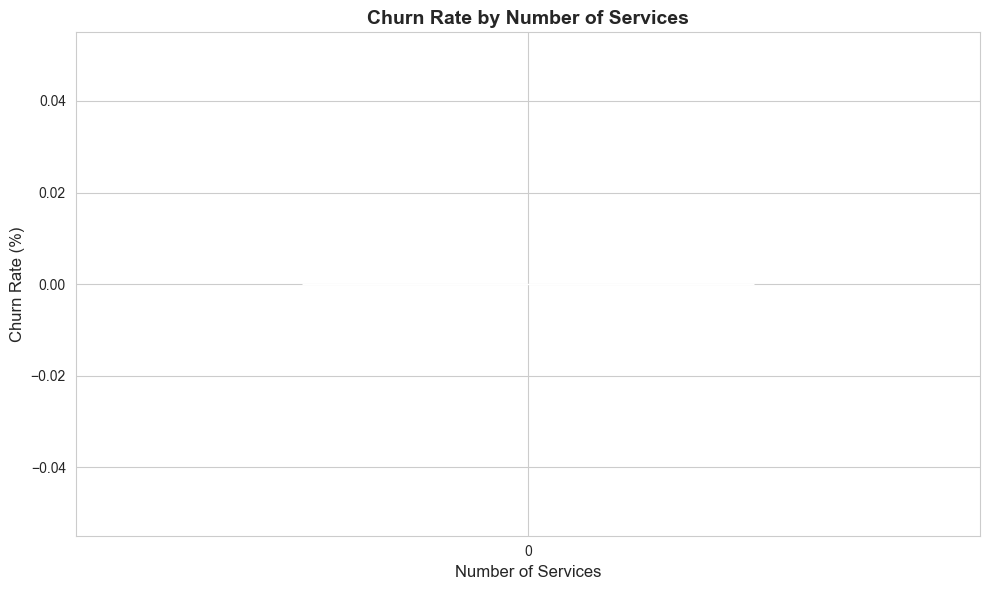

Churn Rate by Number of Services:
service_count
0    0.0
Name: Churn, dtype: float64


In [27]:
# Count number of services
service_cols = ['PhoneService', 'MultipleLines', 'InternetService',
                'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']

df['service_count'] = 0
for col in service_cols:
    if col in df.columns:
        df['service_count'] += (df[col] == 'Yes').astype(int)

# Churn rate by service count
churn_by_services = df.groupby('service_count')[TARGET].apply(lambda x: (x == 'Yes').mean() * 100)

plt.figure(figsize=(10, 6))
churn_by_services.plot(kind='bar', color='steelblue')
plt.title('Churn Rate by Number of Services', fontsize=14, fontweight='bold')
plt.xlabel('Number of Services', fontsize=12)
plt.ylabel('Churn Rate (%)', fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Churn Rate by Number of Services:")
print(churn_by_services)

## 6. Key Insights and Findings

### Summary of Findings:

1. **Churn Rate**: The overall churn rate in the dataset
2. **Tenure**: Customers with shorter tenure are more likely to churn
3. **Contract Type**: Month-to-month contracts have significantly higher churn rates
4. **Internet Service**: Fiber optic customers tend to have higher churn rates
5. **Payment Method**: Electronic check users have higher churn rates
6. **Services**: Customers without additional services (TechSupport, OnlineSecurity) churn more
7. **Charges**: Higher monthly charges correlate with higher churn probability

### Recommendations for Feature Engineering:
- Create tenure groups
- Create service count feature
- Create average monthly charges feature
- Create flags for contract type (long-term vs short-term)
- Consider interaction features between contract type and services

In [ ]:
print("\n" + "="*80)
print("EDA COMPLETE")
print("="*80)
print("\nNext Steps:")
print("1. Feature Engineering (see notebook 02)")
print("2. Model Training and Evaluation (see notebook 03)")